In [2]:
import pandas as pd


data=pd.read_csv('../data/customer-churn.csv')
# print(data)
print(data.describe())
print("------")
print(data.shape)
print("------")
print(data.info())
print("------")
print(data.isna().sum())
print("------")
print(data.duplicated().sum())
data.drop_duplicates(inplace=True)

print(data.dtypes)



       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000
------
(7043, 21)
------
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   M

In [ ]:
# print((data["TotalCharges"].str.strip() == "").sum())

# pour convertir les "" to Nan
data["TotalCharges"]=pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

print(data["TotalCharges"].isna().sum())

data["TotalCharges"]=data["TotalCharges"].fillna(0)
print(data["TotalCharges"].isna().sum())

# virifier les doublons des clients 
print(data["customerID"].duplicated().sum())

# print(data.dtypes)

Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []

[0 rows x 21 columns]
0
0
0


In [ ]:
def detecte_outliers(col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data[col] < lower) |
        (data[col] > upper)
    ]
    return outliers

print("Nombre d'outliers :", len(detecte_outliers("MonthlyCharges")))
print("Nombre d'outliers :", len(detecte_outliers("TotalCharges")))
print("Nombre d'outliers :", len(detecte_outliers("tenure")))

Nombre d'outliers : 0
Nombre d'outliers : 0
Nombre d'outliers : 0


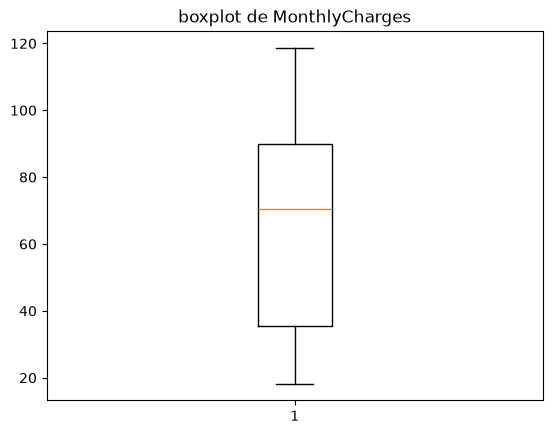

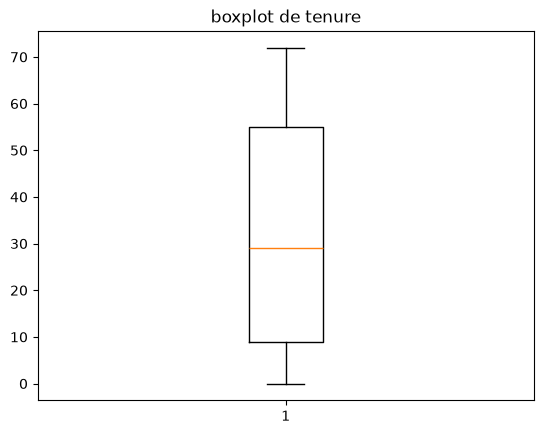

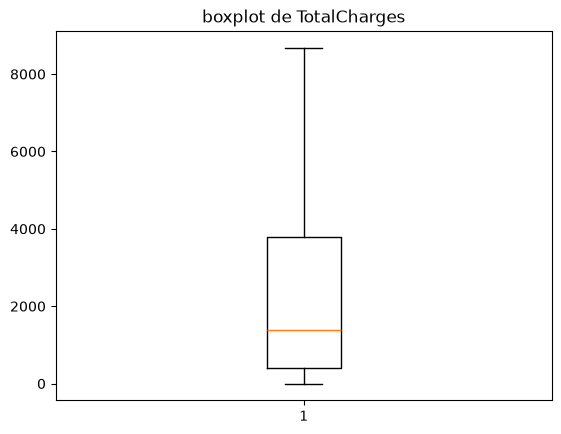

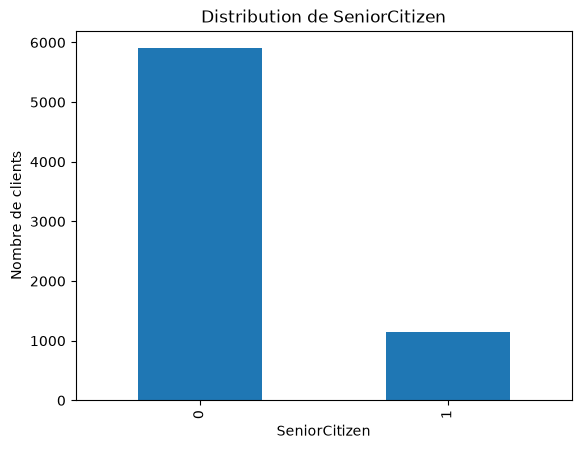

In [38]:
# les 
import matplotlib.pylab as plt
numeric_for_boxplot=[
    "MonthlyCharges",
    "tenure",
    "TotalCharges"
]
for col in numeric_for_boxplot:
    plt.boxplot(data[col])
    plt.title(f"boxplot de {col}")
    plt.show()

data["SeniorCitizen"].value_counts().plot(kind="bar")

plt.title("Distribution de SeniorCitizen")
plt.xlabel("SeniorCitizen")
plt.ylabel("Nombre de clients")
plt.show()

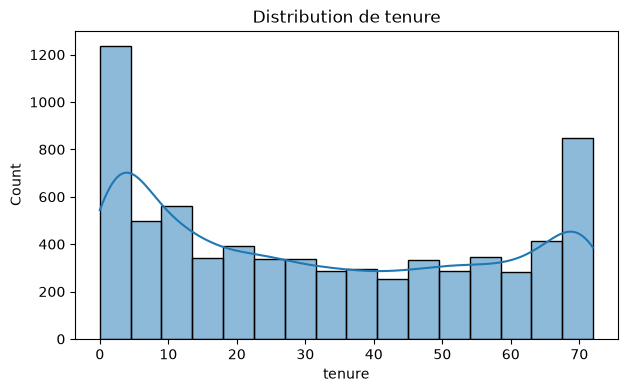

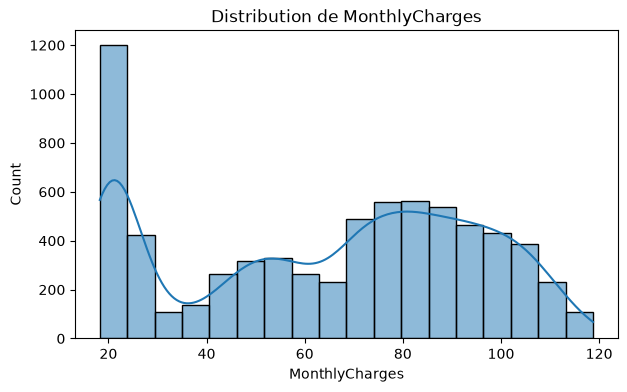

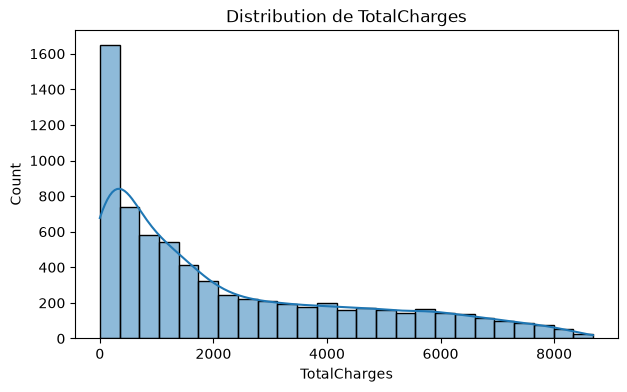

In [47]:
# EDA
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns=[
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

data[numeric_columns].describe()

for col in numeric_columns:
    plt.figure(figsize=(7,4))
    sns.histplot(data[col], kde=True)
    plt.title(f"Distribution de {col}")
    plt.show()

Churn
No     5174
Yes    1869
Name: count, dtype: int64


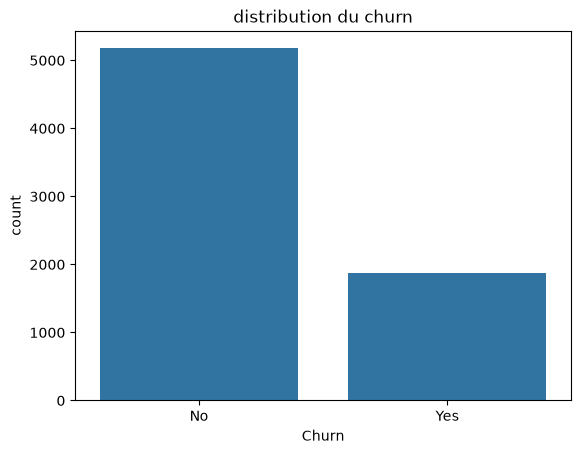

In [51]:
print(data["Churn"].value_counts())

# visualisation du churn
plt.Figure(figsize=(6,4))
sns.countplot(data=data,x="Churn")
plt.title("distribution du churn")
plt.show()

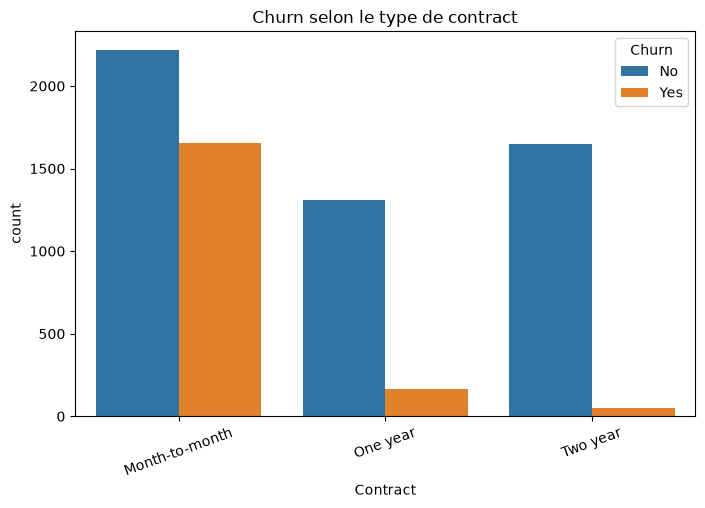

In [54]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=data,
    x="Contract",
    hue="Churn"
)
plt.title("Churn selon le type de contract")
plt.xticks(rotation=20)
plt.show()

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.016567        0.220173      0.103006
tenure               0.016567  1.000000        0.247900      0.826178
MonthlyCharges       0.220173  0.247900        1.000000      0.651174
TotalCharges         0.103006  0.826178        0.651174      1.000000


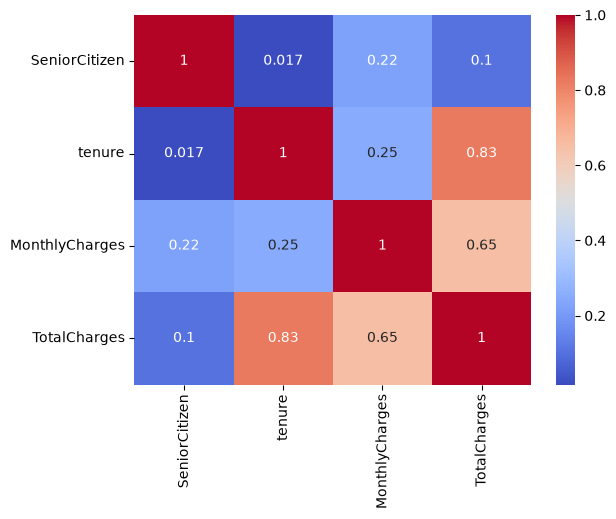

In [66]:
correlation=data[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
].corr()

print(correlation)
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.show()

In [ ]:
data["tenure_group"]=pd.cut(
    data["tenure"],
    bins=[-1,12,24,48,72],
    labels=["0-12","13-24","25-48","49-72"]
)

data["is_new_customer"]=(data["tenure"] <= 6).astype(int)

      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL             No  ...   
1        

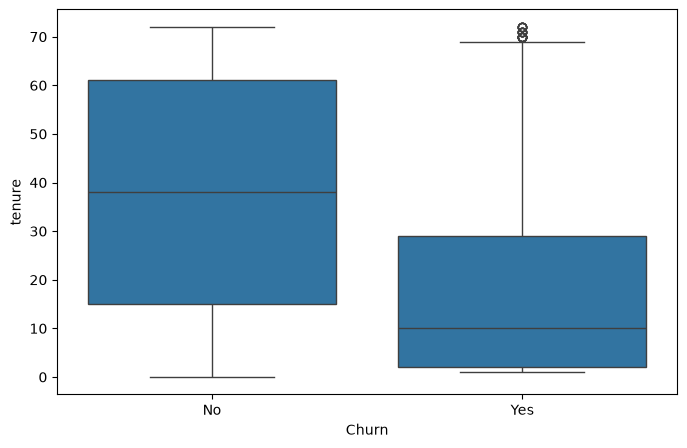

In [ ]:
# anciennete vs churn

plt.figure(figsize=(8,5))
sns.boxplot(data=data,x="Churn",y="tenure")
plt.show()

In [88]:
data.to_csv('../data/customer-churn-clean.csv',index=False,encoding='utf-8')